#Input the image

Saving Screenshot 2024-12-13 111442.png to Screenshot 2024-12-13 111442.png


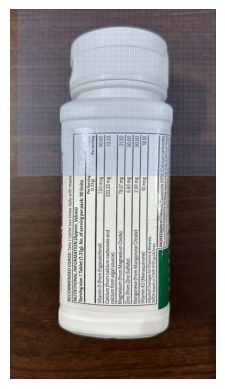

In [1]:
from google.colab import files
import cv2
import matplotlib.pyplot as plt

uploaded = files.upload()

image_name = next(iter(uploaded))

image = cv2.imread(image_name)
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(rgb_image)
plt.axis("off")
plt.show()

In [8]:
import numpy as np

rgb_values = np.array(rgb_image)

print("Image dimensions:", rgb_values.shape)
print("\nRGB values of first 5 pixels:")
print(rgb_values[0, :5, :])

Image dimensions: (754, 419, 3)

RGB values of first 5 pixels:
[[ 97  77  66]
 [102  82  71]
 [101  81  70]
 [101  81  70]
 [101  81  70]]


RGB to HSI conversion

In [9]:
import numpy as np

def rgb_to_hsi(image):
    rgb = image.astype(np.float32) / 255.0
    R, G, B = rgb[:,:,0], rgb[:,:,1], rgb[:,:,2]

    I = (R + G + B) / 3.0

    min_rgb = np.minimum(np.minimum(R, G), B)
    S = 1 - (3 * min_rgb / (R + G + B + 1e-10))

    numerator = 0.5 * ((R-G) + (R-B))
    denominator = np.sqrt((R-G)**2 + (R-B)*(G-B))

    theta = np.arccos(np.clip(
        numerator / (denominator + 1e-10), -1, 1
    ))

    H = np.where(B <= G, theta, 2*np.pi - theta)
    H = H / (2*np.pi)

    return np.stack((H, S, I), axis=2)

#low pass filter

mean/average filter

In [10]:
hsi_image = rgb_to_hsi(rgb_image)

row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

mean_value = np.mean(neighborhood, axis=(0, 1))

print("\nMean HSI values:")
print(mean_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

hsi_image[row, col] = mean_value

print("\nUpdated center pixel after mean filtering:")
print(hsi_image[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18604648 0.3372549 ]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Mean HSI values:
[0.05987628 0.18708721 0.33551198]

Original center pixel:
[0.05987628 0.18604648 0.3372549 ]

Updated center pixel after mean filtering:
[0.05987628 0.18708721 0.33551198]


weighted mean

In [11]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

weights = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32)

weights = weights / np.sum(weights)

weighted_value = np.sum(neighborhood * weights[:, :, np.newaxis], axis=(0, 1))

print("\nWeighted Mean HSI values:")
print(weighted_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

hsi_image[row, col] = weighted_value

print("\nUpdated center pixel after weighted mean filtering:")
print(hsi_image[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18708721 0.33551198]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Weighted Mean HSI values:
[0.05987628 0.18705125 0.33559373]

Original center pixel:
[0.05987628 0.18708721 0.33551198]

Updated center pixel after weighted mean filtering:
[0.05987628 0.18705125 0.33559373]


Gaussian filter

In [13]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

gaussian_mask = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32)

gaussian_mask = gaussian_mask / 16

gaussian_value = np.sum(
    neighborhood * gaussian_mask[:, :, np.newaxis],
    axis=(0, 1)
)

print("\nGaussian filtered HSI values:")
print(gaussian_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

gaussian_hsi = hsi_image.copy()
gaussian_hsi[row, col] = gaussian_value

print("\nUpdated center pixel after Gaussian filtering:")
print(gaussian_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Gaussian filtered HSI values:
[0.05987628 0.18704225 0.33561414]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after Gaussian filtering:
[0.05987628 0.18704225 0.33561414]


Median filter

In [14]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

median_value = np.median(neighborhood, axis=(0, 1))

print("\nMedian HSI values:")
print(median_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

median_hsi = hsi_image.copy()

median_hsi[row, col] = median_value

print("\nUpdated center pixel after median filtering:")
print(median_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Median HSI values:
[0.05987628 0.18823528 0.33333334]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after median filtering:
[0.05987628 0.18823528 0.33333334]


#Sharpening filters

Laplacian filter

In [15]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

laplacian_mask = np.array([
    [0,  1, 0],
    [1, -4, 1],
    [0,  1, 0]
], dtype=np.float32)

laplacian_value = np.sum(
    neighborhood * laplacian_mask[:, :, np.newaxis],
    axis=(0, 1)
)

print("\nLaplacian HSI values:")
print(laplacian_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

laplacian_hsi = hsi_image.copy()

laplacian_hsi[row, col] = laplacian_value

print("\nUpdated center pixel after Laplacian filtering:")
print(laplacian_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Laplacian HSI values:
[ 0.         -0.00147241  0.00272316]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after Laplacian filtering:
[ 0.         -0.00147241  0.00272316]


Sobel filters

In [16]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

sobel_x = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

sobel_y = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=np.float32)

Gx = np.sum(neighborhood * sobel_x[:, :, np.newaxis], axis=(0, 1))
Gy = np.sum(neighborhood * sobel_y[:, :, np.newaxis], axis=(0, 1))

sobel_value = np.sqrt(Gx**2 + Gy**2)

print("\nHorizontal gradient (Gx):")
print(Gx)

print("\nVertical gradient (Gy):")
print(Gy)

print("\nSobel gradient magnitude:")
print(sobel_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

sobel_hsi = hsi_image.copy()
sobel_hsi[row, col] = sobel_value

print("\nUpdated center pixel after Sobel filtering:")
print(sobel_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Horizontal gradient (Gx):
[ 0.          0.01925129 -0.03529412]

Vertical gradient (Gy):
[-3.7252903e-09  2.8624952e-02 -5.0980479e-02]

Sobel gradient magnitude:
[3.7252903e-09 3.4496374e-02 6.2005512e-02]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after Sobel filtering:
[3.7252903e-09 3.4496374e-02 6.2005512e-02]


High-boost filter

In [17]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

average_mask = np.array([
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
], dtype=np.float32) / 9

blurred_value = np.sum(
    neighborhood * average_mask[:, :, np.newaxis],
    axis=(0, 1)
)

print("\nBlurred HSI values:")
print(blurred_value)

mask_value = hsi_image[row, col] - blurred_value

print("\nHigh-frequency mask:")
print(mask_value)

A = 2
high_boost_value = hsi_image[row, col] + (A - 1) * mask_value

print("\nHigh-boost HSI values:")
print(high_boost_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

high_boost_hsi = hsi_image.copy()
high_boost_hsi[row, col] = high_boost_value

print("\nUpdated center pixel after high-boost filtering:")
print(high_boost_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Blurred HSI values:
[0.05987629 0.18719883 0.3353274 ]

High-frequency mask:
[-3.7252903e-09 -1.4758110e-04  2.6634336e-04]

High-boost HSI values:
[0.05987628 0.18690367 0.33586007]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after high-boost filtering:
[0.05987628 0.18690367 0.33586007]


#Frequency domain filtering

ideal low pass

In [18]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

D0 = 1.0
u = np.arange(3) - 1
v = np.arange(3) - 1
U, V = np.meshgrid(u, v)
D = np.sqrt(U**2 + V**2)

ILPF = np.where(D <= D0, 1, 0)

print("\nIdeal Low-Pass Filter Mask:")
print(ILPF)

filtered_values = []

for channel in range(3):
    F = np.fft.fft2(neighborhood[:, :, channel])
    F_shifted = np.fft.fftshift(F)

    G = F_shifted * ILPF

    G_unshifted = np.fft.ifftshift(G)
    filtered = np.fft.ifft2(G_unshifted).real

    filtered_values.append(filtered[1, 1])

ilpf_value = np.array(filtered_values)

print("\nIdeal Low-Pass Filter HSI values:")
print(ilpf_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

ilpf_hsi = hsi_image.copy()
ilpf_hsi[row, col] = ilpf_value

print("\nUpdated center pixel after Ideal Low-Pass filtering:")
print(ilpf_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Ideal Low-Pass Filter Mask:
[[0 1 0]
 [1 1 1]
 [0 1 0]]

Ideal Low-Pass Filter HSI values:
[0.05987628 0.18641284 0.33676775]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after Ideal Low-Pass filtering:
[0.05987628 0.18641284 0.33676776]


Butterworth low pass

In [19]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

D0 = 1.0
n = 2
u = np.arange(3) - 1
v = np.arange(3) - 1
U, V = np.meshgrid(u, v)
D = np.sqrt(U**2 + V**2)

BLPF = 1 / (1 + (D / D0)**(2 * n))

print("\nButterworth Low-Pass Filter Mask:")
print(BLPF)

filtered_values = []
for channel in range(3):
    F = np.fft.fft2(neighborhood[:, :, channel])
    F_shifted = np.fft.fftshift(F)

    G = F_shifted * BLPF

    G_unshifted = np.fft.ifftshift(G)
    filtered = np.fft.ifft2(G_unshifted).real

    filtered_values.append(filtered[1, 1])

blpf_value = np.array(filtered_values)
print("\nButterworth Low-Pass Filter HSI values:")
print(blpf_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

blpf_hsi = hsi_image.copy()
blpf_hsi[row, col] = blpf_value

print("\nUpdated center pixel after Butterworth Low-Pass filtering:")
print(blpf_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Butterworth Low-Pass Filter Mask:
[[0.2 0.5 0.2]
 [0.5 1.  0.5]
 [0.2 0.5 0.2]]

Butterworth Low-Pass Filter HSI values:
[0.05987628 0.18693353 0.33581278]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after Butterworth Low-Pass filtering:
[0.05987628 0.18693353 0.33581278]


Gaussian low pass

In [20]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

D0 = 1.0
u = np.arange(3) - 1
v = np.arange(3) - 1
U, V = np.meshgrid(u, v)
D = np.sqrt(U**2 + V**2)
GLPF = np.exp(-(D**2) / (2 * D0**2))

print("\nGaussian Low-Pass Filter Mask:")
print(GLPF)

filtered_values = []
for channel in range(3):
    F = np.fft.fft2(neighborhood[:, :, channel])
    F_shifted = np.fft.fftshift(F)
    G = F_shifted * GLPF
    G_unshifted = np.fft.ifftshift(G)
    filtered = np.fft.ifft2(G_unshifted).real
    filtered_values.append(filtered[1, 1])

glpf_value = np.array(filtered_values)

print("\nGaussian Low-Pass Filter HSI values:")
print(glpf_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

glpf_hsi = hsi_image.copy()
glpf_hsi[row, col] = glpf_value

print("\nUpdated center pixel after Gaussian Low-Pass filtering:")
print(glpf_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Gaussian Low-Pass Filter Mask:
[[0.36787944 0.60653066 0.36787944]
 [0.60653066 1.         0.60653066]
 [0.36787944 0.60653066 0.36787944]]

Gaussian Low-Pass Filter HSI values:
[0.05987628 0.18695697 0.33576912]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after Gaussian Low-Pass filtering:
[0.05987628 0.18695697 0.33576912]


high pass

In [21]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

D0 = 1.0
u = np.arange(3) - 1
v = np.arange(3) - 1
U, V = np.meshgrid(u, v)
D = np.sqrt(U**2 + V**2)

IHPF = np.where(D > D0, 1, 0)

print("\nIdeal High-Pass Filter Mask:")
print(IHPF)

filtered_values = []
for channel in range(3):
    F = np.fft.fft2(neighborhood[:, :, channel])
    F_shifted = np.fft.fftshift(F)

    G = F_shifted * IHPF

    G_unshifted = np.fft.ifftshift(G)
    filtered = np.fft.ifft2(G_unshifted).real

    filtered_values.append(filtered[1, 1])

ihpf_value = np.array(filtered_values)

print("\nIdeal High-Pass Filter HSI values:")
print(ihpf_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

ihpf_hsi = hsi_image.copy()
ihpf_hsi[row, col] = ihpf_value

print("\nUpdated center pixel after Ideal High-Pass filtering:")
print(ihpf_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Ideal High-Pass Filter Mask:
[[1 0 1]
 [0 0 0]
 [1 0 1]]

Ideal High-Pass Filter HSI values:
[ 0.          0.00063841 -0.00117403]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after Ideal High-Pass filtering:
[ 0.          0.00063841 -0.00117403]


#Image restoration

#Spatial Noise Restoration Filters

Arithematic mean

In [22]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

mean_value = np.sum(neighborhood, axis=(0, 1)) / 9

print("\nArithmetic Mean HSI values:")
print(mean_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

arithmetic_mean_hsi = hsi_image.copy()
arithmetic_mean_hsi[row, col] = mean_value

print("\nUpdated center pixel after arithmetic mean filtering:")
print(arithmetic_mean_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Arithmetic Mean HSI values:
[0.05987628 0.18719885 0.33532742]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after arithmetic mean filtering:
[0.05987628 0.18719885 0.33532742]


Geometric mean

In [23]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

geometric_value = np.prod(neighborhood, axis=(0, 1)) ** (1/9)

print("\nGeometric Mean HSI values:")
print(geometric_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

geometric_mean_hsi = hsi_image.copy()
geometric_mean_hsi[row, col] = geometric_value

print("\nUpdated center pixel after geometric mean filtering:")
print(geometric_mean_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Geometric Mean HSI values:
[0.05987628 0.1871621  0.33526137]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after geometric mean filtering:
[0.05987628 0.1871621  0.33526137]


Harmonic mean

In [24]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

harmonic_value = 9 / np.sum(1 / (neighborhood + 1e-10), axis=(0, 1))

print("\nHarmonic Mean HSI values:")
print(harmonic_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

harmonic_mean_hsi = hsi_image.copy()
harmonic_mean_hsi[row, col] = harmonic_value

print("\nUpdated center pixel after harmonic mean filtering:")
print(harmonic_mean_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Harmonic Mean HSI values:
[0.05987628 0.18712524 0.33519554]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after harmonic mean filtering:
[0.05987628 0.18712524 0.33519554]


ContraHarmonic mean

In [25]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

Q = 1.5

numerator = np.sum(neighborhood ** (Q + 1), axis=(0, 1))
denominator = np.sum(neighborhood ** Q, axis=(0, 1))

contraharmonic_value = numerator / (denominator + 1e-10)

print("\nContraharmonic Mean HSI values:")
print(contraharmonic_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

contraharmonic_mean_hsi = hsi_image.copy()
contraharmonic_mean_hsi[row, col] = contraharmonic_value

print("\nUpdated center pixel after contraharmonic mean filtering:")
print(contraharmonic_mean_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Contraharmonic Mean HSI values:
[0.05987628 0.18730861 0.3355264 ]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after contraharmonic mean filtering:
[0.05987628 0.18730861 0.3355264 ]


#Order Statistics filter

Median filter

In [26]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

median_value = np.median(neighborhood, axis=(0, 1))

print("\nMedian HSI values:")
print(median_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

median_hsi = hsi_image.copy()
median_hsi[row, col] = median_value

print("\nUpdated center pixel after median filtering:")
print(median_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Median HSI values:
[0.05987628 0.18823528 0.33333334]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after median filtering:
[0.05987628 0.18823528 0.33333334]


Min and max filter

In [27]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

min_value = np.min(neighborhood, axis=(0, 1))
max_value = np.max(neighborhood, axis=(0, 1))

print("\nMinimum HSI values:")
print(min_value)

print("\nMaximum HSI values:")
print(max_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

min_hsi = hsi_image.copy()
max_hsi = hsi_image.copy()

min_hsi[row, col] = min_value
max_hsi[row, col] = max_value

print("\nUpdated center pixel after minimum filtering:")
print(min_hsi[row, col])

print("\nUpdated center pixel after maximum filtering:")
print(max_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Minimum HSI values:
[0.05987628 0.18181819 0.3254902 ]

Maximum HSI values:
[0.05987628 0.19277108 0.34509805]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after minimum filtering:
[0.05987628 0.18181819 0.3254902 ]

Updated center pixel after maximum filtering:
[0.05987628 0.19277108 0.34509805]


Midpoint filter

In [28]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

min_value = np.min(neighborhood, axis=(0, 1))
max_value = np.max(neighborhood, axis=(0, 1))

midpoint_value = (min_value + max_value) / 2

print("\nMidpoint HSI values:")
print(midpoint_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

midpoint_hsi = hsi_image.copy()
midpoint_hsi[row, col] = midpoint_value

print("\nUpdated center pixel after midpoint filtering:")
print(midpoint_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Midpoint HSI values:
[0.05987628 0.18729463 0.33529413]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after midpoint filtering:
[0.05987628 0.18729463 0.33529413]


Alpha trimmed

In [31]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]
print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

d = 2

sorted_values = np.sort(neighborhood.reshape(9, 3), axis=0)
trimmed_values = sorted_values[d//2:9-d//2, :]
alpha_trimmed_value = np.sum(trimmed_values, axis=0) / (9-d)

print("\nAlpha-Trimmed Mean HSI values:")
print(alpha_trimmed_value)

print("\nOriginal center pixel:")
print(hsi_image[row, col])

alpha_trimmed_hsi = hsi_image.copy()
alpha_trimmed_hsi[row, col] = alpha_trimmed_value

print("\nUpdated center pixel after alpha-trimmed mean filtering:")
print(alpha_trimmed_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Alpha-Trimmed Mean HSI values:
[0.05987629 0.18717149 0.33533692]

Original center pixel:
[0.05987628 0.18705125 0.33559373]

Updated center pixel after alpha-trimmed mean filtering:
[0.05987629 0.18717149 0.33533692]


#Frequency Domain Periodic Noise Filters

Band reject

In [32]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]
print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

D0 = 1
W = 1
u = np.arange(3) - 1
v = np.arange(3) - 1
U, V = np.meshgrid(u, v)
D = np.sqrt(U**2 + V**2)

band_reject_mask = np.where(
    (D >= D0 - W/2) & (D <= D0 + W/2),
    0,
    1
)

print("\nBand Reject Filter Mask:")
print(band_reject_mask)

filtered_values = []
for channel in range(3):
    F = np.fft.fft2(neighborhood[:, :, channel])
    F_shifted = np.fft.fftshift(F)
    G = F_shifted * band_reject_mask
    G_unshifted = np.fft.ifftshift(G)
    filtered = np.fft.ifft2(G_unshifted).real
    filtered_values.append(filtered[1, 1])

band_reject_value = np.array(filtered_values)
print("\nBand Reject Filter HSI values:")
print(band_reject_value)

band_reject_hsi = hsi_image.copy()
band_reject_hsi[row, col] = band_reject_value

print("\nUpdated center pixel after Band Reject filtering:")
print(band_reject_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Band Reject Filter Mask:
[[0 0 0]
 [0 1 0]
 [0 0 0]]

Band Reject Filter HSI values:
[0.05987628 0.18719885 0.33532741]

Updated center pixel after Band Reject filtering:
[0.05987628 0.18719885 0.33532742]


band pass

In [33]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]
print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

D0 = 1
W = 1
u = np.arange(3) - 1
v = np.arange(3) - 1
U, V = np.meshgrid(u, v)
D = np.sqrt(U**2 + V**2)

band_pass_mask = np.where(
    (D >= D0 - W/2) & (D <= D0 + W/2),
    1,
    0
)

print("\nBand Pass Filter Mask:")
print(band_pass_mask)

filtered_values = []
for channel in range(3):
    F = np.fft.fft2(neighborhood[:, :, channel])
    F_shifted = np.fft.fftshift(F)
    G = F_shifted * band_pass_mask
    G_unshifted = np.fft.ifftshift(G)
    filtered = np.fft.ifft2(G_unshifted).real
    filtered_values.append(filtered[1, 1])

band_pass_value = np.array(filtered_values)
print("\nBand Pass Filter HSI values:")
print(band_pass_value)

band_pass_hsi = hsi_image.copy()
band_pass_hsi[row, col] = band_pass_value

print("\nUpdated center pixel after Band Pass filtering:")
print(band_pass_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Band Pass Filter Mask:
[[1 1 1]
 [1 0 1]
 [1 1 1]]

Band Pass Filter HSI values:
[ 0.         -0.0001476   0.00026631]

Updated center pixel after Band Pass filtering:
[ 0.         -0.0001476   0.00026631]


notch reject

In [34]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]

print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

D0 = 1

u = np.arange(3) - 1
v = np.arange(3) - 1
U, V = np.meshgrid(u, v)

D1 = np.sqrt((U - 1)**2 + V**2)
D2 = np.sqrt((U + 1)**2 + V**2)

notch_reject_mask = np.where(
    (D1 <= D0) | (D2 <= D0),
    0,
    1
)

print("\nNotch Reject Filter Mask:")
print(notch_reject_mask)

filtered_values = []

for channel in range(3):
    F = np.fft.fft2(neighborhood[:, :, channel])
    F_shifted = np.fft.fftshift(F)
    G = F_shifted * notch_reject_mask
    G_unshifted = np.fft.ifftshift(G)
    filtered = np.fft.ifft2(G_unshifted).real
    filtered_values.append(filtered[1, 1])

notch_reject_value = np.array(filtered_values)

print("\nNotch Reject Filter HSI values:")
print(notch_reject_value)

notch_reject_hsi = hsi_image.copy()
notch_reject_hsi[row, col] = notch_reject_value

print("\nUpdated center pixel after Notch Reject filtering:")
print(notch_reject_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Notch Reject Filter Mask:
[[0 1 0]
 [0 0 0]
 [0 1 0]]

Notch Reject Filter HSI values:
[ 0.         -0.00149728  0.00268095]

Updated center pixel after Notch Reject filtering:
[ 0.         -0.00149728  0.00268095]


notch pass

In [35]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]
print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

D0 = 1
u = np.arange(3) - 1
v = np.arange(3) - 1
U, V = np.meshgrid(u, v)
D1 = np.sqrt((U - 1)**2 + V**2)
D2 = np.sqrt((U + 1)**2 + V**2)

notch_pass_mask = np.where(
    (D1 <= D0) | (D2 <= D0),
    1,
    0
)

print("\nNotch Pass Filter Mask:")
print(notch_pass_mask)

filtered_values = []
for channel in range(3):
    F = np.fft.fft2(neighborhood[:, :, channel])
    F_shifted = np.fft.fftshift(F)
    G = F_shifted * notch_pass_mask
    G_unshifted = np.fft.ifftshift(G)
    filtered = np.fft.ifft2(G_unshifted).real
    filtered_values.append(filtered[1, 1])

notch_pass_value = np.array(filtered_values)
print("\nNotch Pass Filter HSI values:")
print(notch_pass_value)

notch_pass_hsi = hsi_image.copy()
notch_pass_hsi[row, col] = notch_pass_value

print("\nUpdated center pixel after Notch Pass filtering:")
print(notch_pass_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Notch Pass Filter Mask:
[[1 0 1]
 [1 1 1]
 [1 0 1]]

Notch Pass Filter HSI values:
[0.05987628 0.18854853 0.33291277]

Updated center pixel after Notch Pass filtering:
[0.05987628 0.18854854 0.33291277]


#Deconvolution Filters

inverse filtering

In [36]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]
print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

psf = np.array([
    [0, 0, 0],
    [0, 1, 0],
    [0, 0, 0]
], dtype=np.float32)

inverse_values = []
for channel in range(3):
    F = np.fft.fft2(neighborhood[:, :, channel])
    H = np.fft.fft2(psf)

    H[np.abs(H) < 1e-10] = 1e-10
    G = F / H

    restored = np.fft.ifft2(G).real
    inverse_values.append(restored[1, 1])

inverse_value = np.array(inverse_values)
print("\nInverse Filter HSI values:")
print(inverse_value)

inverse_hsi = hsi_image.copy()
inverse_hsi[row, col] = inverse_value

print("\nUpdated center pixel after Inverse filtering:")
print(inverse_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Inverse Filter HSI values:
[0.05987629 0.19047618 0.3294118 ]

Updated center pixel after Inverse filtering:
[0.05987629 0.19047618 0.3294118 ]


Weiner filter

In [37]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]
print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

psf = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32) / 16

K = 0.01

wiener_values = []
for channel in range(3):
    F = np.fft.fft2(neighborhood[:, :, channel])
    H = np.fft.fft2(psf)

    H_conjugate = np.conjugate(H)
    G = (H_conjugate / (np.abs(H)**2 + K)) * F

    restored = np.fft.ifft2(G).real
    wiener_values.append(restored[1, 1])

wiener_value = np.array(wiener_values)
print("\nWiener Filter HSI values:")
print(wiener_value)

wiener_hsi = hsi_image.copy()
wiener_hsi[row, col] = wiener_value

print("\nUpdated center pixel after Wiener filtering:")
print(wiener_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Wiener Filter HSI values:
[0.05928345 0.19398068 0.3164295 ]

Updated center pixel after Wiener filtering:
[0.05928345 0.19398068 0.3164295 ]


Constrained Least Squares Filter

In [38]:
row = 10
col = 10

neighborhood = hsi_image[row-1:row+2, col-1:col+2, :]
print("Original 3x3 HSI neighbourhood:")
print(neighborhood)

psf = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float32) / 16

laplacian = np.array([
    [0, -1, 0],
    [-1, 4, -1],
    [0, -1, 0]
], dtype=np.float32)

gamma = 0.01

cls_values = []
for channel in range(3):
    F = np.fft.fft2(neighborhood[:, :, channel])
    H = np.fft.fft2(psf)
    P = np.fft.fft2(laplacian)

    H_conjugate = np.conjugate(H)
    G = (H_conjugate / (np.abs(H)**2 + gamma * np.abs(P)**2 + 1e-10)) * F

    restored = np.fft.ifft2(G).real
    cls_values.append(restored[1, 1])

cls_value = np.array(cls_values)
print("\nConstrained Least Squares HSI values:")
print(cls_value)

cls_hsi = hsi_image.copy()
cls_hsi[row, col] = cls_value

print("\nUpdated center pixel after CLS filtering:")
print(cls_hsi[row, col])

Original 3x3 HSI neighbourhood:
[[[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18390805 0.34117648]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.18181819 0.34509805]
  [0.05987628 0.18705125 0.33559373]
  [0.05987628 0.18823528 0.33333334]]

 [[0.05987628 0.19047618 0.32941177]
  [0.05987628 0.19277108 0.3254902 ]
  [0.05987628 0.19047618 0.32941177]]]

Constrained Least Squares HSI values:
[0.05987629 0.19631147 0.31886628]

Updated center pixel after CLS filtering:
[0.05987629 0.19631147 0.31886628]
